# Spam Mail Prediction using Machine Learning
**Intern:** Shashank Deshmukh  |  **Company:** Naviotech Solutions Pvt Ltd  |  **Guide:** Mr. Md. Ameen
**University:** Bharati Vidyapeeth (Deemed to be University)

**Goal:** classify a text message as *spam* or *ham* (not spam).
**Approach:** text cleaning -> TF-IDF features -> 4 ML models -> evaluation -> prediction on new messages.

## 1. Import libraries

In [1]:
import re, string, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

## 2. Load the dataset
SMS Spam Collection (5,572 messages labelled *ham* or *spam*).

In [2]:
URL = 'https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv'
df = pd.read_csv(URL, sep='\t', header=None, names=['label','message'])
print('Shape:', df.shape)
df.head(10)

Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## 3. Explore the data

In [3]:
print(df['label'].value_counts())
print('\nMissing values:\n', df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df['target'] = df['label'].map({'ham':0,'spam':1})
df['length'] = df['message'].str.len()
print('Shape after removing duplicates:', df.shape)

label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
 label      0
message    0
dtype: int64

Duplicate rows: 403
Shape after removing duplicates: (5169, 4)


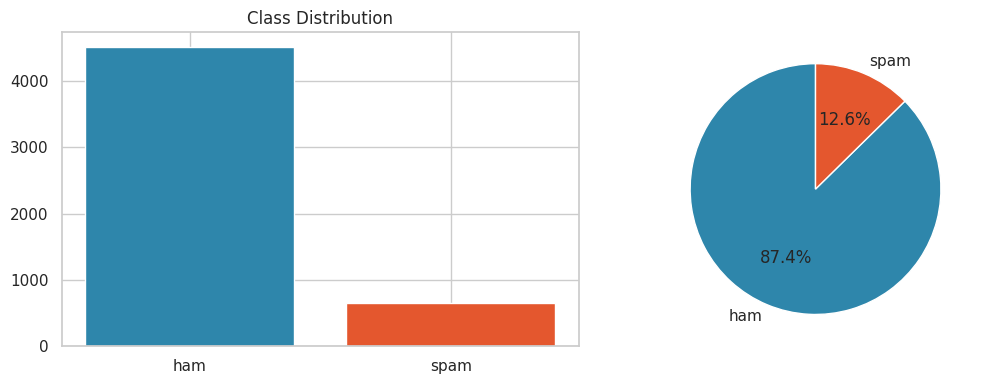

In [4]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
counts = df['label'].value_counts()
ax[0].bar(counts.index, counts.values, color=['#2e86ab','#e4572e']); ax[0].set_title('Class Distribution')
ax[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', colors=['#2e86ab','#e4572e'], startangle=90)
plt.tight_layout(); plt.show()

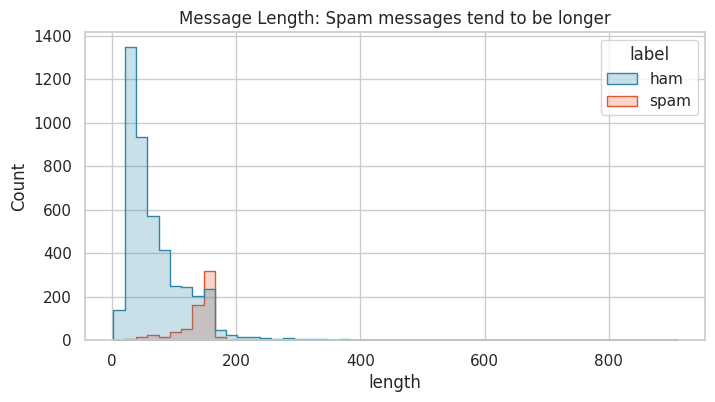

label
ham      70.9
spam    137.7
Name: length, dtype: float64


In [5]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x='length', hue='label', bins=50, palette=['#2e86ab','#e4572e'], element='step')
plt.title('Message Length: Spam messages tend to be longer'); plt.show()
print(df.groupby('label')['length'].mean().round(1))

## 4. Clean the text
Lowercase -> replace URLs and long numbers with tokens -> remove punctuation -> remove stop-words.

In [6]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' urltoken ', text)
    text = re.sub(r'\d{5,}', ' longnumber ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    return ' '.join(w for w in text.split() if w not in ENGLISH_STOP_WORDS)

df['clean'] = df['message'].apply(clean_text)
print('BEFORE:', df['message'][2]); print('AFTER :', df['clean'][2])

BEFORE: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
AFTER : free entry 2 wkly comp win fa cup final tkts 21st 2005 text fa longnumber receive entry questionstd txt ratetcs apply longnumber over18s


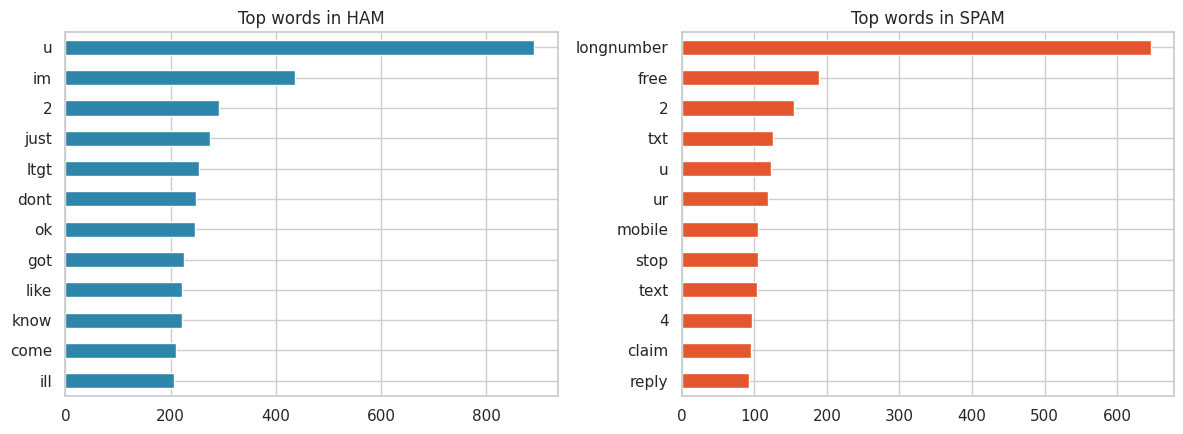

In [7]:
def top_words(s, n=12): return pd.Series(' '.join(s).split()).value_counts().head(n)
fig, ax = plt.subplots(1,2, figsize=(12,4.5))
top_words(df[df.target==0]['clean'])[::-1].plot.barh(ax=ax[0], color='#2e86ab'); ax[0].set_title('Top words in HAM')
top_words(df[df.target==1]['clean'])[::-1].plot.barh(ax=ax[1], color='#e4572e'); ax[1].set_title('Top words in SPAM')
plt.tight_layout(); plt.show()

## 5. Train / test split (80% / 20%, stratified)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['target'], test_size=0.2, stratify=df['target'], random_state=42)
print('Train:', len(X_train), ' Test:', len(X_test))

Train: 4135  Test: 1034


## 6. Build and train the models
Each model is a Pipeline: **TF-IDF (unigrams + bigrams)** -> classifier.

In [9]:
def make_pipe(clf):
    return Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True)), ('clf', clf)])

models = {
    'Naive Bayes': MultinomialNB(alpha=0.1),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=10, class_weight='balanced'),
    'Linear SVM': LinearSVC(C=1, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
}
fitted, preds, scores, rows = {}, {}, {}, []
for name, clf in models.items():
    pipe = make_pipe(clf)
    print('Training', name, '...')
    pipe.fit(X_train, y_train)
    yp = pipe.predict(X_test)
    s = pipe.predict_proba(X_test)[:,1] if hasattr(pipe,'predict_proba') else pipe.decision_function(X_test)
    fitted[name], preds[name], scores[name] = pipe, yp, s
    rows.append({'Model':name,'Accuracy':accuracy_score(y_test,yp),'Precision':precision_score(y_test,yp),
                 'Recall':recall_score(y_test,yp),'F1':f1_score(y_test,yp),'ROC_AUC':roc_auc_score(y_test,s)})
print('Done.')

Training Naive Bayes ...
Training Logistic Regression ...


Training Linear SVM ...
Training Random Forest ...


Done.


## 7. Compare the models

In [10]:
res = pd.DataFrame(rows).sort_values('F1', ascending=False).reset_index(drop=True)
display(res.round(4))
best_name = res.loc[0,'Model']; print('Best model (by F1):', best_name)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Naive Bayes,0.9874,0.9836,0.9160,0.9486,0.9905
1,Random Forest,0.9855,1.0000,0.8855,0.9393,0.9931
2,Logistic Regression,0.9836,0.9524,0.9160,0.9339,0.9948
3,Linear SVM,0.9836,0.9672,0.9008,0.9328,0.9947


Best model (by F1): Naive Bayes


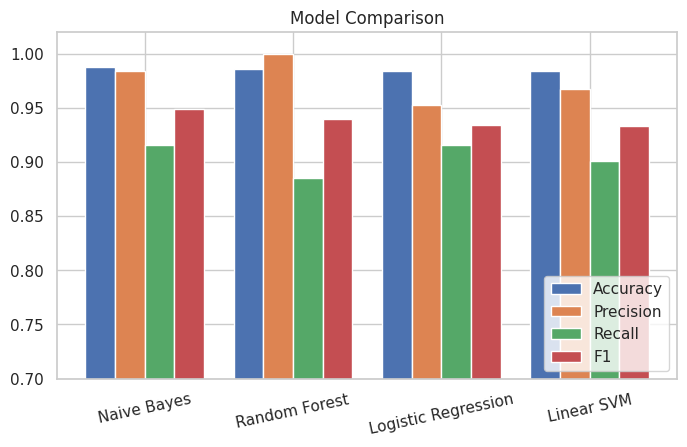

In [11]:
x = np.arange(len(res)); w = 0.2
plt.figure(figsize=(8,4.5))
for i,m in enumerate(['Accuracy','Precision','Recall','F1']): plt.bar(x+i*w, res[m], w, label=m)
plt.xticks(x+1.5*w, res['Model'], rotation=12); plt.ylim(0.7,1.02); plt.legend(loc='lower right'); plt.title('Model Comparison'); plt.show()

## 8. Detailed evaluation of the best model

              precision    recall  f1-score   support

         Ham     0.9879    0.9978    0.9928       903
        Spam     0.9836    0.9160    0.9486       131

    accuracy                         0.9874      1034
   macro avg     0.9858    0.9569    0.9707      1034
weighted avg     0.9874    0.9874    0.9872      1034



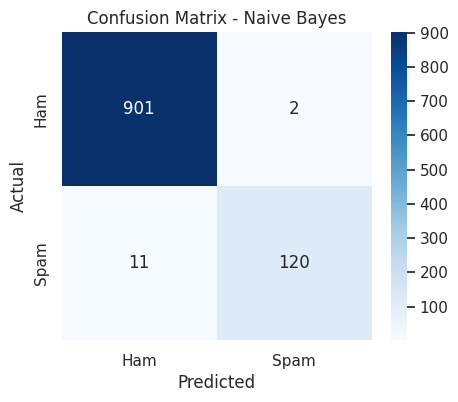

In [12]:
print(classification_report(y_test, preds[best_name], target_names=['Ham','Spam'], digits=4))
cm = confusion_matrix(y_test, preds[best_name])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham','Spam'], yticklabels=['Ham','Spam'])
plt.title('Confusion Matrix - '+best_name); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

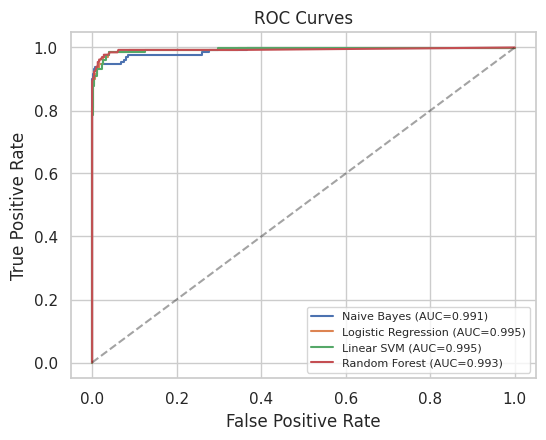

In [13]:
plt.figure(figsize=(6,4.5))
for n in fitted:
    fpr,tpr,_ = roc_curve(y_test, scores[n]); plt.plot(fpr,tpr,label=f'{n} (AUC={roc_auc_score(y_test,scores[n]):.3f})')
plt.plot([0,1],[0,1],'k--',alpha=.4); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves'); plt.legend(fontsize=8); plt.show()

## 9. Final prediction on new messages

In [14]:
best = fitted[best_name]
def predict_message(msg):
    return 'SPAM' if best.predict([clean_text(msg)])[0]==1 else 'HAM (not spam)'

samples = [
 'Congratulations! You have won a free iPhone. Click http://win-prize.com now to claim',
 'Hey, are we still meeting for lunch at 1 pm tomorrow?',
 'URGENT! Your account is suspended. Call 09061701461 to claim your 1000 pound cash prize',
 'Please send me the internship report draft by evening']
print('FINAL PREDICTIONS'); print('-'*60)
for s in samples: print(f'[{predict_message(s):15s}] {s}')

FINAL PREDICTIONS
------------------------------------------------------------
[SPAM           ] Congratulations! You have won a free iPhone. Click http://win-prize.com now to claim
[HAM (not spam) ] Hey, are we still meeting for lunch at 1 pm tomorrow?
[SPAM           ] URGENT! Your account is suspended. Call 09061701461 to claim your 1000 pound cash prize
[HAM (not spam) ] Please send me the internship report draft by evening


In [15]:
# Try your own message
my_msg = input('Type a message: ') if False else 'Free entry! Text WIN to 80086 to get a 500 pound prize'
print(predict_message(my_msg))

SPAM


## 10. Conclusion
Multinomial Naive Bayes with TF-IDF reached about **98.7% accuracy** and **98.4% precision** on unseen messages.
Future work: deep learning (LSTM / BERT), email datasets, a web app (Streamlit/Flask).